<a href="https://colab.research.google.com/github/231230028-Tia/231230028-Tia-Pengantar-ML/blob/main/praktikum_3_visualisasi_data_titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
# Memuat dataset Titanic dari Seaborn
df = sns.load_dataset("titanic")

# Menampilkan lima baris pertama
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data setiap kolom:")
print(df.dtypes)

print("\nInformasi dataset:")
df.info()


Jumlah baris dan kolom: (891, 15)

Nama kolom:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Tipe data setiap kolom:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non

In [4]:
# Memeriksa missing values
missing = pd.DataFrame({
    "Jumlah Data Kosong": df.isna().sum(),
    "Persentase Data Kosong (%)": (df.isna().mean() * 100).round(2)
})

display(missing.sort_values("Jumlah Data Kosong", ascending=False))

,Jumlah Data Kosong,Persentase Data Kosong (%)
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


In [5]:
# Membuat label status survival agar grafik mudah dibaca
df["survival_status"] = df["survived"].map({
    0: "Tidak Selamat",
    1: "Selamat"
})

print("Jumlah penumpang:", len(df))
print("Jumlah penumpang selamat:", int(df["survived"].sum()))
print("Jumlah penumpang tidak selamat:", int((df["survived"] == 0).sum()))
print(f"Persentase keselamatan keseluruhan: {df['survived'].mean() * 100:.2f}%")

Jumlah penumpang: 891
Jumlah penumpang selamat: 342
Jumlah penumpang tidak selamat: 549
Persentase keselamatan keseluruhan: 38.38%


In [6]:
# Menghitung survival rate berdasarkan jenis kelamin dan kelas
sex_rate = (
    df.groupby("sex", observed=True)["survived"]
      .mean().mul(100).round(2)
)

class_rate = (
    df.groupby("class", observed=True)["survived"]
      .mean().mul(100).round(2)
)

# Membuat kelompok usia
age_df = df.dropna(subset=["age"]).copy()
age_df["kelompok_usia"] = pd.cut(
    age_df["age"],
    bins=[0, 12, 18, 35, 60, np.inf],
    labels=[
        "Anak (0-12)",
        "Remaja (13-18)",
        "Dewasa muda (19-35)",
        "Dewasa (36-60)",
        "Lansia (>60)"
    ],
    include_lowest=True
)

age_rate = (
    age_df.groupby("kelompok_usia", observed=True)["survived"]
          .mean().mul(100).round(2)
)

print("Survival rate berdasarkan jenis kelamin (%):")
display(sex_rate.to_frame("Survival Rate (%)"))

print("Survival rate berdasarkan kelas (%):")
display(class_rate.to_frame("Survival Rate (%)"))

print("Survival rate berdasarkan kelompok usia (%):")
display(age_rate.to_frame("Survival Rate (%)"))

Survival rate berdasarkan jenis kelamin (%):


,Survival Rate (%)
sex,
female,74.20
male,18.89


Survival rate berdasarkan kelas (%):


,Survival Rate (%)
class,
First,62.96
Second,47.28
Third,24.24


Survival rate berdasarkan kelompok usia (%):


,Survival Rate (%)
kelompok_usia,
Anak (0-12),57.97
Remaja (13-18),42.86
Dewasa muda (19-35),38.27
Dewasa (36-60),40.00
Lansia (>60),22.73


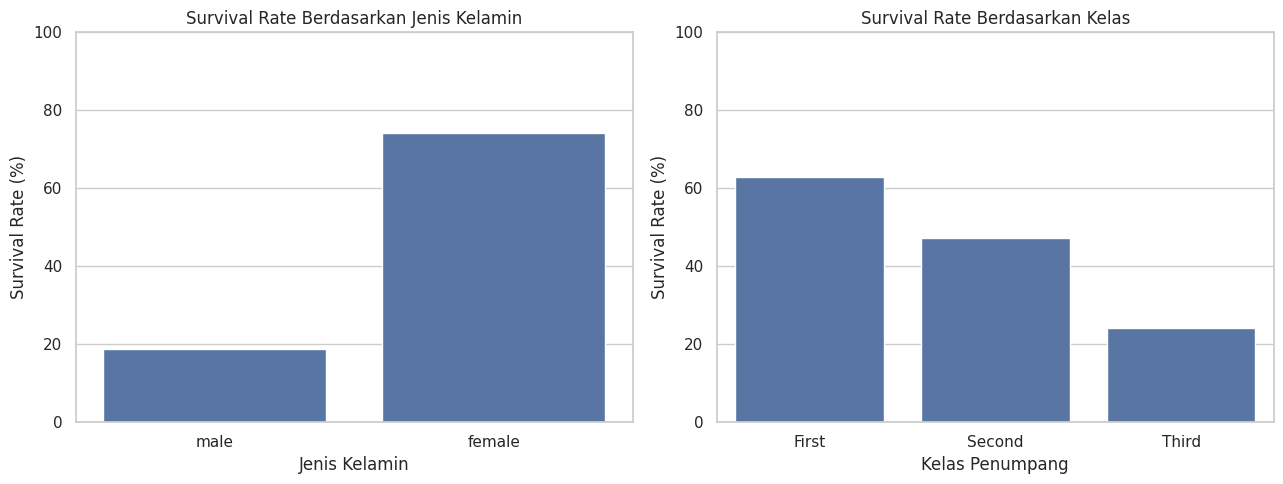

In [7]:
# Visualisasi perbandingan survival rate berdasarkan gender dan kelas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=df, x="sex", y="survived",
    estimator=lambda values: values.mean() * 100,
    errorbar=None, ax=axes[0]
)
axes[0].set_title("Survival Rate Berdasarkan Jenis Kelamin")
axes[0].set_xlabel("Jenis Kelamin")
axes[0].set_ylabel("Survival Rate (%)")
axes[0].set_ylim(0, 100)

sns.barplot(
    data=df, x="class", y="survived",
    order=["First", "Second", "Third"],
    estimator=lambda values: values.mean() * 100,
    errorbar=None, ax=axes[1]
)
axes[1].set_title("Survival Rate Berdasarkan Kelas")
axes[1].set_xlabel("Kelas Penumpang")
axes[1].set_ylabel("Survival Rate (%)")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

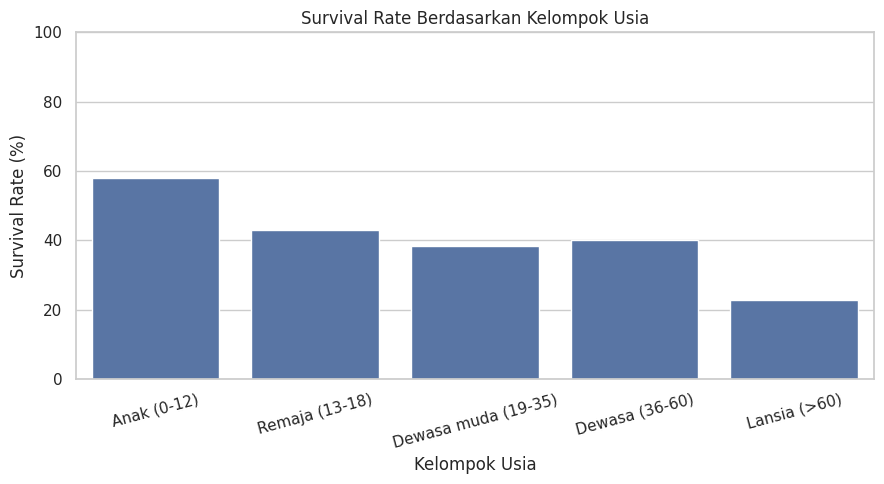

In [8]:
# Visualisasi survival rate berdasarkan kelompok usia
plt.figure(figsize=(9, 5))
sns.barplot(x=age_rate.index.astype(str), y=age_rate.values)

plt.title("Survival Rate Berdasarkan Kelompok Usia")
plt.xlabel("Kelompok Usia")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

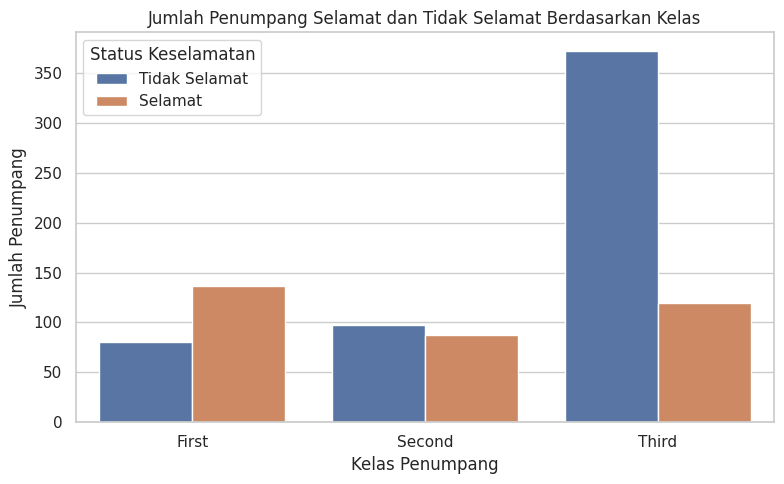

,jumlah_penumpang,jumlah_selamat,jumlah_tidak_selamat,survival_rate
class,,,,
First,216,136,80,62.96
Second,184,87,97,47.28
Third,491,119,372,24.24


In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="class",
    hue="survival_status",
    order=["First", "Second", "Third"],
    hue_order=["Tidak Selamat", "Selamat"]
)

plt.title("Jumlah Penumpang Selamat dan Tidak Selamat Berdasarkan Kelas")
plt.xlabel("Kelas Penumpang")
plt.ylabel("Jumlah Penumpang")
plt.legend(title="Status Keselamatan")
plt.tight_layout()
plt.show()

# Tabel ringkasan kelas penumpang
class_summary = df.groupby("class", observed=True).agg(
    jumlah_penumpang=("survived", "size"),
    jumlah_selamat=("survived", "sum"),
    jumlah_tidak_selamat=("survived", lambda values: (values == 0).sum()),
    survival_rate=("survived", "mean")
)

class_summary["survival_rate"] = (
    class_summary["survival_rate"] * 100
).round(2)

display(class_summary)

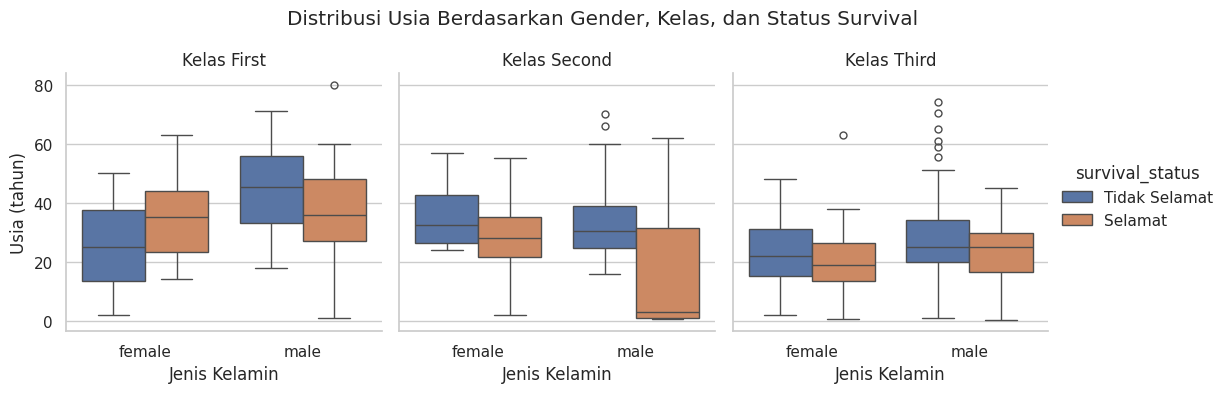

In [10]:
age_plot = df.dropna(subset=["age"]).copy()
age_plot["survival_status"] = age_plot["survived"].map({
    0: "Tidak Selamat",
    1: "Selamat"
})

g = sns.catplot(
    data=age_plot,
    x="sex",
    y="age",
    hue="survival_status",
    col="class",
    kind="box",
    order=["female", "male"],
    hue_order=["Tidak Selamat", "Selamat"],
    col_order=["First", "Second", "Third"],
    height=4,
    aspect=0.9
)

g.set_axis_labels("Jenis Kelamin", "Usia (tahun)")
g.set_titles("Kelas {col_name}")
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("Distribusi Usia Berdasarkan Gender, Kelas, dan Status Survival")
plt.show()

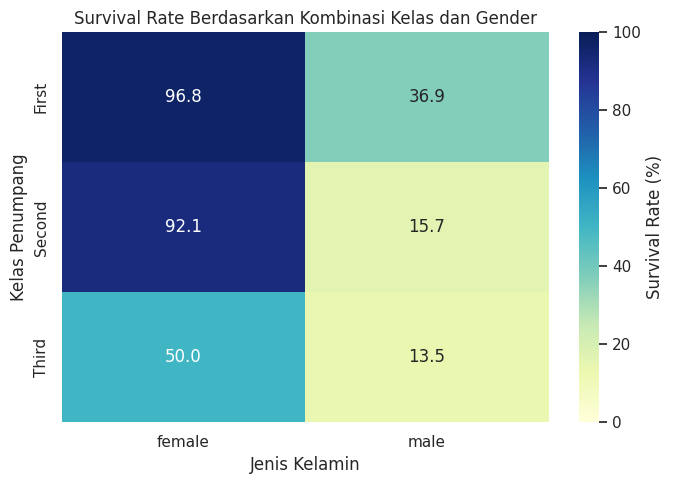

sex,female,male
class,,
First,96.81,36.89
Second,92.11,15.74
Third,50.00,13.54


In [11]:
# Heatmap survival rate pada kombinasi kelas dan gender
interaction_table = df.pivot_table(
    index="class",
    columns="sex",
    values="survived",
    aggfunc="mean",
    observed=True
) * 100

plt.figure(figsize=(7, 5))
sns.heatmap(
    interaction_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Survival Rate (%)"}
)

plt.title("Survival Rate Berdasarkan Kombinasi Kelas dan Gender")
plt.xlabel("Jenis Kelamin")
plt.ylabel("Kelas Penumpang")
plt.tight_layout()
plt.show()

display(interaction_table.round(2))

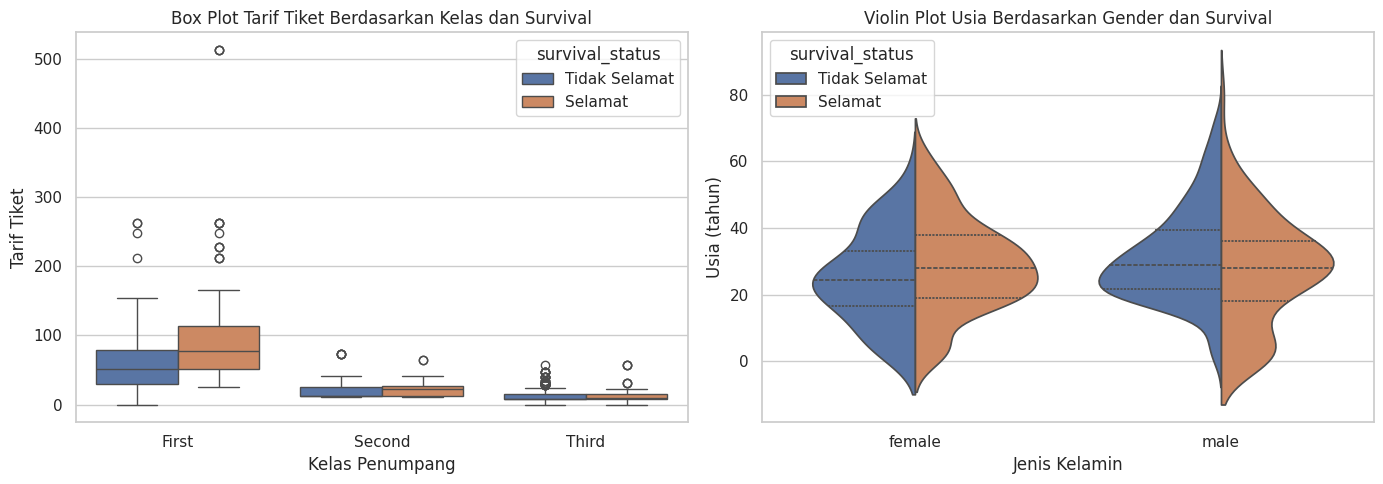

In [12]:
mixed_df = df.dropna(subset=["age", "fare"]).copy()
mixed_df["survival_status"] = mixed_df["survived"].map({
    0: "Tidak Selamat",
    1: "Selamat"
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=mixed_df,
    x="class",
    y="fare",
    hue="survival_status",
    order=["First", "Second", "Third"],
    ax=axes[0]
)
axes[0].set_title("Box Plot Tarif Tiket Berdasarkan Kelas dan Survival")
axes[0].set_xlabel("Kelas Penumpang")
axes[0].set_ylabel("Tarif Tiket")

sns.violinplot(
    data=mixed_df,
    x="sex",
    y="age",
    hue="survival_status",
    order=["female", "male"],
    split=True,
    inner="quart",
    ax=axes[1]
)
axes[1].set_title("Violin Plot Usia Berdasarkan Gender dan Survival")
axes[1].set_xlabel("Jenis Kelamin")
axes[1].set_ylabel("Usia (tahun)")

plt.tight_layout()
plt.show()

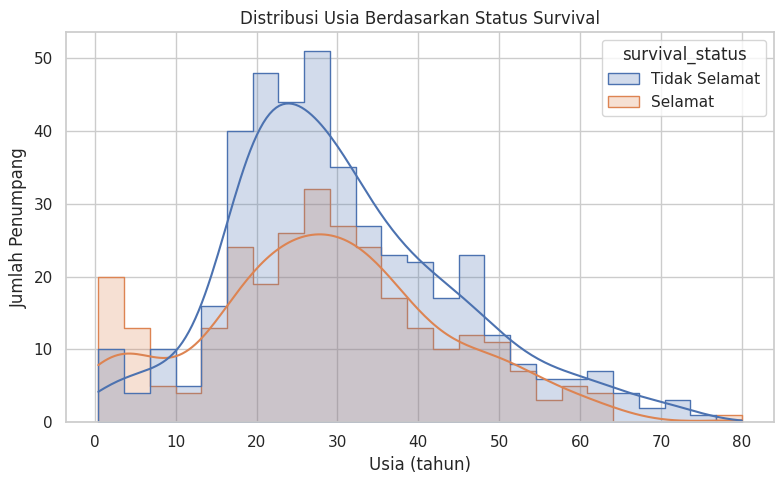

In [13]:
# Histogram untuk melihat distribusi usia
plt.figure(figsize=(8, 5))

sns.histplot(
    data=age_plot,
    x="age",
    hue="survival_status",
    bins=25,
    kde=True,
    element="step"
)

plt.title("Distribusi Usia Berdasarkan Status Survival")
plt.xlabel("Usia (tahun)")
plt.ylabel("Jumlah Penumpang")
plt.tight_layout()
plt.show()

Ringkasan survival berdasarkan deck:


,jumlah_penumpang,jumlah_selamat,survival_rate
deck,,,
A,15,7,46.67
B,47,35,74.47
C,59,35,59.32
D,33,25,75.76
E,32,24,75.00
F,13,8,61.54
G,4,2,50.00


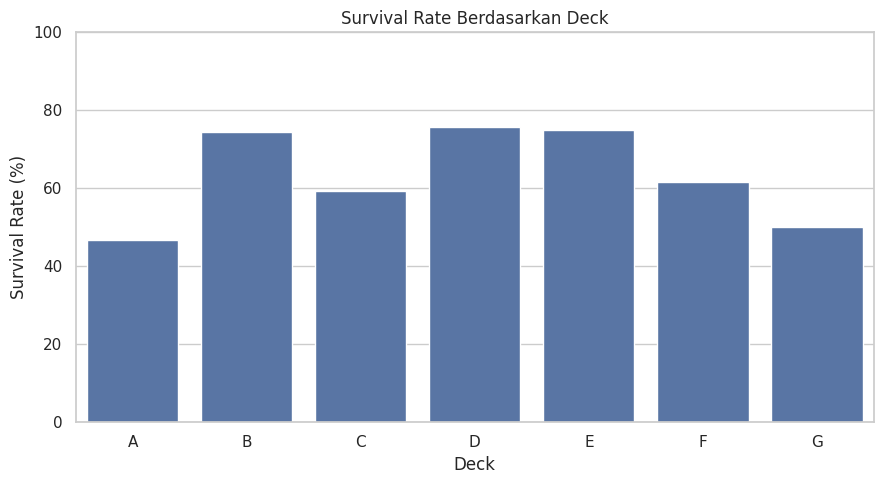

Jumlah data deck tersedia: 203
Jumlah data deck kosong: 688


In [14]:
# Analisis survival berdasarkan deck
deck_df = df.dropna(subset=["deck"]).copy()

deck_summary = deck_df.groupby("deck", observed=True).agg(
    jumlah_penumpang=("survived", "size"),
    jumlah_selamat=("survived", "sum"),
    survival_rate=("survived", "mean")
)

deck_summary["survival_rate"] = (
    deck_summary["survival_rate"] * 100
).round(2)

print("Ringkasan survival berdasarkan deck:")
display(deck_summary)

plt.figure(figsize=(9, 5))
deck_order = sorted(deck_df["deck"].astype(str).unique())

sns.barplot(
    data=deck_df,
    x="deck",
    y="survived",
    order=deck_order,
    estimator=lambda values: values.mean() * 100,
    errorbar=None
)

plt.title("Survival Rate Berdasarkan Deck")
plt.xlabel("Deck")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("Jumlah data deck tersedia:", len(deck_df))
print("Jumlah data deck kosong:", int(df["deck"].isna().sum()))

Ringkasan survival berdasarkan pelabuhan keberangkatan:


,jumlah_penumpang,jumlah_selamat,survival_rate
embarked,,,
C,168,93,55.36
Q,77,30,38.96
S,644,217,33.70


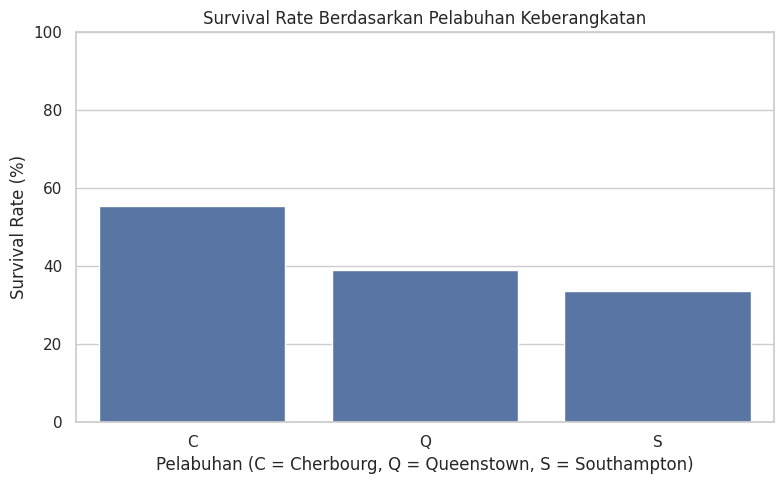

In [15]:
# Analisis survival berdasarkan pelabuhan keberangkatan
embarked_df = df.dropna(subset=["embarked"]).copy()

embarked_summary = embarked_df.groupby("embarked", observed=True).agg(
    jumlah_penumpang=("survived", "size"),
    jumlah_selamat=("survived", "sum"),
    survival_rate=("survived", "mean")
)

embarked_summary["survival_rate"] = (
    embarked_summary["survival_rate"] * 100
).round(2)

print("Ringkasan survival berdasarkan pelabuhan keberangkatan:")
display(embarked_summary)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=embarked_df,
    x="embarked",
    y="survived",
    order=["C", "Q", "S"],
    estimator=lambda values: values.mean() * 100,
    errorbar=None
)

plt.title("Survival Rate Berdasarkan Pelabuhan Keberangkatan")
plt.xlabel("Pelabuhan (C = Cherbourg, Q = Queenstown, S = Southampton)")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [16]:
print("========== RINGKASAN ANALISIS TITANIC ==========")
print(f"Survival rate keseluruhan: {df['survived'].mean() * 100:.2f}%")

print("\nJenis kelamin dengan survival rate tertinggi:")
print(f"{sex_rate.idxmax()} ({sex_rate.max():.2f}%)")

print("\nKelas dengan survival rate tertinggi:")
print(f"{class_rate.idxmax()} ({class_rate.max():.2f}%)")

print("\nKelompok usia dengan survival rate tertinggi:")
print(f"{age_rate.idxmax()} ({age_rate.max():.2f}%)")

if not deck_summary.empty:
    print("\nDeck dengan survival rate tertinggi (dari data deck yang tersedia):")
    print(
        f"{deck_summary['survival_rate'].idxmax()} "
        f"({deck_summary['survival_rate'].max():.2f}%)"
    )

print("\nPelabuhan dengan survival rate tertinggi:")
print(
    f"{embarked_summary['survival_rate'].idxmax()} "
    f"({embarked_summary['survival_rate'].max():.2f}%)"
)

========== RINGKASAN ANALISIS TITANIC ==========
Survival rate keseluruhan: 38.38%

Jenis kelamin dengan survival rate tertinggi:
female (74.20%)

Kelas dengan survival rate tertinggi:
First (62.96%)

Kelompok usia dengan survival rate tertinggi:
Anak (0-12) (57.97%)

Deck dengan survival rate tertinggi (dari data deck yang tersedia):
D (75.76%)

Pelabuhan dengan survival rate tertinggi:
C (55.36%)
